# 01. Full baseline: ResNet50 and ViT-B/16

Evaluate both models on all 50,000 validation images. Run cells in order. Matched accuracy has not been established.

## 1. Setup

Select the project `.venv` kernel. Reduce `BATCH_SIZE` if GPU memory is limited.

In [1]:
from collections import Counter
from io import BytesIO
import json
import re

from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import torch
import torchvision
from torchvision.models import (
    ResNet50_Weights, ViT_B_16_Weights, resnet50, vit_b_16,
)
from IPython.display import display
from tqdm.auto import tqdm

from pathlib import Path

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

# Ưu tiên GPU nếu có CUDA; nếu không thì dùng CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR = REPO_ROOT / "data/imagenet/data"
RESULTS_DIR = REPO_ROOT / "results/metrics/baseline_notebook"
# Số ảnh xử lý cùng lúc; giảm nếu thiếu bộ nhớ GPU.
BATCH_SIZE = 32
full_summary = None

Selected device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


c:\Users\ADMIN\Documents\Ky7\CV\cnn-vit-interpretability\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load validation metadata

Read filenames and labels from the existing 14 shards. Image bytes are loaded later in batches.

In [ ]:
validation_files = sorted(DATA_DIR.glob("validation-*.parquet"))
expected_names = [f"validation-{i:05d}-of-00014.parquet" for i in range(14)]
if [parquet_file.name for parquet_file in validation_files] != expected_names:
    raise RuntimeError("Expected all 14 local validation shards. No data will be downloaded.")

print("Validation files:", len(validation_files))
print(pq.ParquetFile(validation_files[0]).schema_arrow)

mapping_verified = False
image_records = []
class_names = None
label_synsets = {}
class_counts = Counter()
for parquet_file in validation_files:
    # Đọc metadata nằm sẵn trong file trên máy, không kết nối Hugging Face.
    metadata = pq.ParquetFile(parquet_file).schema_arrow.metadata or {}
    if b"huggingface" not in metadata:
        raise RuntimeError(f"Cannot verify class mapping: missing metadata in {parquet_file.name}")
    # Lấy thông tin các cột; mục label chứa danh sách tên lớp.
    features = json.loads(metadata[b"huggingface"])["info"]["features"]
    shard_names = features.get("label", {}).get("names")
    if not isinstance(shard_names, list) or len(shard_names) != 1000:
        raise RuntimeError(f"Cannot verify the 1,000 class names in {parquet_file.name}")
    # Lưu tên lớp từ file đầu tiên làm mốc đối chiếu các file còn lại.
    if class_names is None:
        class_names = shard_names
    if shard_names != class_names:
        raise RuntimeError("Class metadata differs between validation shards.")

    # Đọc tên ảnh và label thật
    table = pq.read_table(parquet_file, columns=["image.path", "label"])
    image_ids = table.column(0).to_pylist()
    true_labels = table.column(1).to_pylist()
    for image_id, label in zip(image_ids, true_labels):
        match = re.fullmatch(r"ILSVRC2012_val_\d{8}_(n\d{8})\.JPEG", image_id or "")
        if not match or not isinstance(label, int) or not 0 <= label < 1000:
            raise RuntimeError(f"Invalid filename or label: {image_id}, {label}")
        # Lấy mã lớp từ tên ảnh, ví dụ n01824575.
        synset = match.group(1)
        if label in label_synsets and label_synsets[label] != synset:
            raise RuntimeError(f"Label {label} refers to multiple synsets.")
        label_synsets[label] = synset
        # Đếm ảnh theo lớp; lưu tên ảnh và nhãn vào danh sách dùng để đánh giá.
        class_counts[label] += 1
        image_records.append({"dataset_index": len(image_records), "image_id": image_id, "label": label})

Validation files: 14
image: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
label: int64
-- schema metadata --
huggingface: '{"info": {"features": {"image": {"_type": "Image"}, "label"' + 24715


## 3. Verify labels

Check 50,000 unique images and 1,000 classes. Labels must match torchvision indices, including the three verified naming aliases.

In [3]:
# Kiểm tra đủ ảnh, không trùng; mỗi lớp cần đúng 50 ảnh.
if len(image_records) != 50000 or len({row["image_id"] for row in image_records}) != 50000:
    raise RuntimeError("Expected exactly 50,000 unique validation images.")
if set(class_counts) != set(range(1000)) or set(class_counts.values()) != {50}:
    raise RuntimeError("Expected labels 0 to 999, with 50 images per class.")
ordered_synsets = [label_synsets[label] for label in range(1000)]
if len(set(ordered_synsets)) != 1000 or ordered_synsets != sorted(ordered_synsets):
    raise RuntimeError("Class indices do not follow ImageNet's sorted synset order.")

print("Verified:", len(image_records), "images and", len(class_counts), "classes.")
display(pd.DataFrame(image_records).head())

# Chọn đúng hai bộ weights của dự án và đối chiếu thứ tự lớp.
resnet_weights = ResNet50_Weights.IMAGENET1K_V2
vit_weights = ViT_B_16_Weights.IMAGENET1K_V1
model_categories = resnet_weights.meta["categories"]
if model_categories != vit_weights.meta["categories"]:
    raise RuntimeError("The models have different output class mappings.")

# Ba tên lớp khác cách viết; dùng synset để xác nhận, không đổi chỉ số nhãn.
aliases = {
    134: ("crane", "crane bird", "n02012849"),
    517: ("crane2", "crane", "n03126707"),
    639: ("maillot, tank suit", "maillot tank suit", "n03710721"),
}
for label, dataset_name in enumerate(class_names):
    if label in aliases:
        compatible = (dataset_name, model_categories[label], label_synsets[label]) == aliases[label]
    else:
        compatible = model_categories[label] in dataset_name.split(", ")
    if not compatible:
        raise RuntimeError(f"Cannot verify class index {label}: {dataset_name!r}. Do not guess.")

mapping_verified = True
print("All 1,000 dataset labels are compatible with both torchvision models.")

Verified: 50000 images and 1000 classes.


,dataset_index,image_id,label
0,0,ILSVRC2012_val_00027555_n01824575.JPEG,91
1,1,ILSVRC2012_val_00006054_n02091032.JPEG,171
2,2,ILSVRC2012_val_00027621_n09472597.JPEG,980
3,3,ILSVRC2012_val_00006947_n02102177.JPEG,218
4,4,ILSVRC2012_val_00048107_n01592084.JPEG,19


All 1,000 dataset labels are compatible with both torchvision models.


## 4. Preview images

Display three images with their ground-truth labels.

In [4]:
# Đọc ba ảnh mẫu cùng nhãn thật để kiểm tra trực quan.
preview_batch = next(pq.ParquetFile(validation_files[0]).iter_batches(batch_size=3))
preview_rows = preview_batch.to_pylist()
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, row in zip(axes, preview_rows):
    label = row["label"]
    # Giải mã byte ảnh trong bộ nhớ và chuyển sang RGB trước khi preprocessing.
    with Image.open(BytesIO(row["image"]["bytes"])) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{label}: {model_categories[label]}")
    ax.axis("off")
plt.tight_layout()
plt.show()
del preview_batch, preview_rows

## 5. Read image batches

Apply the model-specific transform while reading small batches to limit RAM usage.

In [5]:
def read_batches(transform):
    images, labels, image_ids = [], [], []
    for parquet_file in validation_files:
        for batch in pq.ParquetFile(parquet_file).iter_batches(batch_size=64, columns=["image", "label"]):
            for row in batch.to_pylist():
                # Giải mã byte ảnh trong bộ nhớ và chuyển sang RGB trước khi preprocessing.
                with Image.open(BytesIO(row["image"]["bytes"])) as image:
                    images.append(transform(image.convert("RGB")))
                labels.append(row["label"])
                image_ids.append(row["image"]["path"])
                if len(images) == BATCH_SIZE:
                    # Ghép ảnh thành tensor batch rồi trả về để model xử lý.
                    yield torch.stack(images), labels, image_ids
                    images, labels, image_ids = [], [], []
    # Xử lý cả batch cuối nếu chưa đủ BATCH_SIZE ảnh.
    if images:
        # Ghép ảnh thành tensor batch rồi trả về để model xử lý.
        yield torch.stack(images), labels, image_ids

## 6. Predict

Disable gradients and record the five highest-scoring classes. Keep the prediction-count check so missing images cannot silently affect accuracy.

In [6]:
def predict(model, transform):
    prediction_rows = []
    num_batches = (len(image_records) + BATCH_SIZE - 1) // BATCH_SIZE
    # Tắt gradient vì chỉ đánh giá, giúp giảm bộ nhớ sử dụng.
    with torch.inference_mode():
        for images, labels, image_ids in tqdm(read_batches(transform), total=num_batches):
            class_scores = model(images.to(device))
            # Chuyển chỉ số lớp dự đoán về CPU để lưu bảng kết quả.
            top5_indices = class_scores.topk(5, dim=1).indices
            top5_indices = top5_indices.cpu().tolist()
            for image_id, label, predicted_classes in zip(image_ids, labels, top5_indices):
                # Lưu 1 nếu đúng, 0 nếu sai để dễ đếm số ảnh dự đoán đúng.
                is_top1_correct = int(predicted_classes[0] == label)
                is_top5_correct = int(label in predicted_classes)
                prediction_rows.append([image_id, label, *predicted_classes, is_top1_correct, is_top5_correct])
            del images, class_scores
    if len(prediction_rows) != len(image_records):
        raise RuntimeError("Expected one prediction for each validation image.")
    columns = ["image_id", "label", "pred_top1", "pred_top2", "pred_top3",
               "pred_top4", "pred_top5", "top1_correct", "top5_correct"]
    return pd.DataFrame(prediction_rows, columns=columns)

## 7. Full evaluation

Run this cell to evaluate all 50,000 images. Accuracy (%) = correct predictions / image count * 100. Save CSVs and release each model before loading the next.

In [7]:
full_summary = None

full_dir = RESULTS_DIR / "full"
full_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame(image_records).to_csv(full_dir / "selected_images.csv", index=False)
if not mapping_verified:
    raise RuntimeError("Verify the dataset labels first.")
full_rows = []
model_settings = [
    ("resnet50", resnet50, resnet_weights),
    ("vit_b_16", vit_b_16, vit_weights),
]
for model_name, create_model, weights in model_settings:
    print("Full evaluation:", model_name)
    transform = weights.transforms()
    # Tải đúng trọng số pretrained và đưa model lên GPU hoặc CPU.
    model = create_model(weights=weights).to(device)
    # Chuyển sang chế độ đánh giá: tắt dropout, dùng thống kê batch normalization đã học.
    model.eval()
    predictions = predict(model, transform)
    # Lưu dự đoán của từng ảnh để kiểm tra và dùng cho thí nghiệm sau.
    predictions.to_csv(full_dir / f"{model_name}_predictions.csv", index=False)
    num_images = len(predictions)
    # Accuracy (%) = số ảnh đúng / tổng số ảnh * 100; sum() đếm các cờ 1.
    top1_accuracy = 100 * predictions["top1_correct"].sum() / num_images
    top5_accuracy = 100 * predictions["top5_correct"].sum() / num_images
    full_rows.append({
        "model": model_name, "weights": str(weights), "device": str(device),
        "num_images": num_images,
        "top1_accuracy_percent": top1_accuracy,
        "top5_accuracy_percent": top5_accuracy,
        "mode": "full",
        "torch_version": torch.__version__, "torchvision_version": torchvision.__version__,
    })
    # Lưu kết quả ngay sau mỗi model, không cần chờ model còn lại.
    pd.DataFrame(full_rows).to_csv(full_dir / "summary.csv", index=False)
    # Giải phóng model trước khi tải model tiếp theo.
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
full_summary = pd.DataFrame(full_rows)

Full evaluation: resnet50


100%|██████████| 1563/1563 [06:25<00:00,  4.06it/s]


Full evaluation: vit_b_16


100%|██████████| 1563/1563 [11:35<00:00,  2.25it/s]


## 8. Compare results

Top-1 gap = ResNet50 accuracy - ViT accuracy, in percentage points (pp).

,model,weights,device,num_images,top1_accuracy_percent,top5_accuracy_percent,mode,torch_version,torchvision_version
0,resnet50,ResNet50_Weights.IMAGENET1K_V2,cuda,50000,80.844,95.432,full,2.5.1+cu121,0.20.1+cu121
1,vit_b_16,ViT_B_16_Weights.IMAGENET1K_V1,cuda,50000,81.066,95.318,full,2.5.1+cu121,0.20.1+cu121


Full Top-1 gap (ResNet - ViT): -0.222 pp


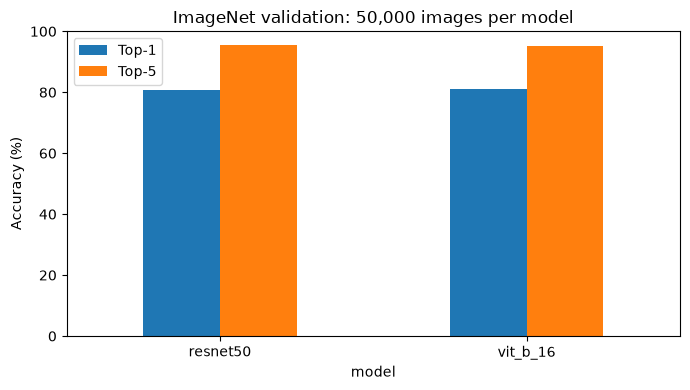

In [8]:
top1 = full_summary.set_index("model")["top1_accuracy_percent"]
# Chênh lệch theo điểm phần trăm; số dương nghĩa là ResNet cao hơn.
full_gap = top1["resnet50"] - top1["vit_b_16"]
full_comparison = pd.DataFrame([{
    "mode": "full", "num_images": len(image_records),
    "resnet50_top1_percent": top1["resnet50"],
    "vit_b_16_top1_percent": top1["vit_b_16"],
    "top1_gap_resnet_minus_vit_pp": full_gap,
    "absolute_top1_gap_pp": abs(full_gap),
}])
full_comparison.to_csv(full_dir / "comparison.csv", index=False)
display(full_summary.round(3))
print(f"Full Top-1 gap (ResNet - ViT): {full_gap:+.3f} pp")
# Vẽ Top-1 và Top-5 của hai model trên cùng thang 0 đến 100%.
chart = full_summary.set_index("model")[["top1_accuracy_percent", "top5_accuracy_percent"]]
chart.columns = ["Top-1", "Top-5"]
ax = chart.plot.bar(figsize=(7, 4), rot=0, ylim=(0, 100))
ax.set_ylabel("Accuracy (%)")
ax.set_title("ImageNet validation: 50,000 images per model")
plt.tight_layout()
plt.show()